# CRISP-DM: Predicting Customer Churn

**Student:** Arti Ramesh Nalawade  
**Student ID:** 020757113  

**About this project:** I am trying to predict which phone/internet customers may leave. I follow six CRISP-DM steps so I can explain not just the model but the whole process.

**Problem:** Can a mobile/telecom company identify customers who may cancel their subscriptions?

# How to use this notebook
1. Upload this `.ipynb` file to Google Colab. Choose **Runtime → Run all**.
2. Kaggle public data are downloaded using `kagglehub`. Some Colab sessions may require Kaggle authentication. If the download fails, a clearly labeled **teaching fallback** runs so you can practice, but **a fallback run does not satisfy the professor's Kaggle-dataset requirement**.
3. Read the Markdown explanations and the outputs. They explain both what happens and why.
4. Download artifacts using the final cell; keep evidence of a real run.
5. Results are computed when you execute cells, and must not be invented in the report.

**Ethics:** This is an educational demonstration, not a production-ready decision system. Do not treat model predictions as certain facts.


## Phase 1: Business understanding
**Stakeholder:** Retention team. **Question:** Which customers may leave? **Target:** `Churn` (`Yes`/`No`). **Business action:** Offer support to high-risk customers. **Success:** compare recall, precision, F1, and ROC AUC; avoid promising financial value without measured costs. **Risks:** false alarms, missing customers, data drift, fairness, privacy.

**Project plan:** understand data → prepare leak-safe features → establish baseline → train → evaluate → demonstrate one prediction → monitor concept.


In [1]:
!pip -q install kagglehub mlxtend joblib


## Phase 2: Data understanding - acquire, describe, explore, verify data quality
The Kaggle dataset contains customer account and service attributes. Count records, check missing data and the target distribution. The fallback is not the same data source.


Using Colab cache for faster access to the 'telco-customer-churn' dataset.
DATA SOURCE: Kaggle: blastchar/telco-customer-churn rows/columns: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


,dtype count
object,18
int64,2
float64,1


Missing values (top):


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


Duplicate rows: 0
Target distribution:


,proportion
Churn,
No,0.73463
Yes,0.26537


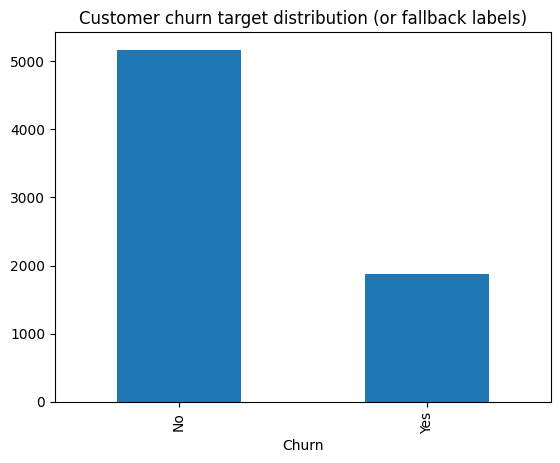

In [2]:
import os, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
DATASET_SOURCE='Kaggle: blastchar/telco-customer-churn'
try:
    import kagglehub
    path=kagglehub.dataset_download('blastchar/telco-customer-churn')
    csvs=glob.glob(os.path.join(path,'**','*.csv'),recursive=True)
    filepath=next(f for f in csvs if 'telco' in os.path.basename(f).lower() or 'churn' in os.path.basename(f).lower())
    df=pd.read_csv(filepath)
except Exception as e:
    warnings.warn('KAGGLE DOWNLOAD FAILED: using an unrelated sklearn teaching fallback; this does NOT meet the required Kaggle provenance. Error: '+str(e)[:180])
    from sklearn.datasets import load_breast_cancer
    ds=load_breast_cancer(as_frame=True)
    df=ds.frame.rename(columns={'target':'Churn'})
    df['Churn']=df['Churn'].map({0:'Yes',1:'No'})
    DATASET_SOURCE='FALLBACK ONLY: sklearn breast cancer (NOT customer churn)'
print('DATA SOURCE:',DATASET_SOURCE,'rows/columns:',df.shape)
display(df.head(),df.dtypes.value_counts().rename('dtype count'))
print('Missing values (top):');display(df.isna().sum().sort_values(ascending=False).head(10))
print('Duplicate rows:',df.duplicated().sum());print('Target distribution:');display(df['Churn'].value_counts(normalize=True))
df['Churn'].value_counts().plot(kind='bar',title='Customer churn target distribution (or fallback labels)');plt.show()


## Phase 3: Data preparation - select, clean, construct, integrate, format
Remove customer IDs (identifiers are not behavioral predictors), convert monetary fields into numbers, and split **before** learning imputation, scaling, or one-hot categories. All learned transformations happen inside a pipeline fitted on training data only.


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay
from sklearn.base import clone
import joblib
work=df.copy()
if 'TotalCharges' in work:work['TotalCharges']=pd.to_numeric(work['TotalCharges'],errors='coerce')
work=work.drop(columns=[x for x in ['customerID','CustomerID'] if x in work],errors='ignore')
assert work['Churn'].notna().all(),'Target contains missing values'
y=work['Churn'].astype(str).str.lower().eq('yes').astype(int)
X=work.drop(columns=['Churn'])
assert len(X)==len(y) and y.nunique()==2
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
num=X.select_dtypes(include=np.number).columns.tolist();cat=X.columns.difference(num).tolist()
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore'))]),cat)])
print('Train:',X_train.shape,'Test:',X_test.shape,'numeric:',len(num),'categorical:',len(cat))
assert set(X_train.index).isdisjoint(set(X_test.index))


Train: (5634, 19) Test: (1409, 19) numeric: 4 categorical: 15


## Phase 4: Modeling - build, validate, select, retrain

**Why an additional split?** Imagine practicing for an exam. Training data are your study notes, validation data are your practice exam, and the test data are the final exam. We should not repeatedly look at the final exam while picking our model.

We use a **stratified validation split** within the original training data, select the model with the highest churn F1 on that validation set, then retrain it on the whole original training set. The final test data remain untouched until Phase 5. F1 balances precision and recall; a real retention team should also evaluate the cost of contacting customers and missing churners.
**In simple words:** I compare a few models on validation data (like a practice test), then choose one without looking at the final test answers.


In [4]:
from sklearn.metrics import precision_score, recall_score, f1_score
# Split only the training portion again; never use X_test or y_test for model selection.
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)
model_candidates = {
    'dummy': DummyClassifier(strategy='most_frequent'),
    'logistic': Pipeline([('prep', clone(pre)), ('model', LogisticRegression(max_iter=1500, random_state=42))]),
    'random_forest': Pipeline([('prep', clone(pre)), ('model', RandomForestClassifier(
        n_estimators=120, min_samples_leaf=3, random_state=42, n_jobs=-1))])
}
validation_rows = {}
for name, candidate in model_candidates.items():
    candidate.fit(X_fit, y_fit)
    val_pred = candidate.predict(X_val)
    validation_rows[name] = {
        'precision': precision_score(y_val, val_pred, zero_division=0),
        'recall': recall_score(y_val, val_pred, zero_division=0),
        'f1': f1_score(y_val, val_pred, zero_division=0),
        'auc': roc_auc_score(y_val, candidate.predict_proba(X_val)[:,1])
    }
results = pd.DataFrame(validation_rows).T.sort_values('f1', ascending=False)
print('VALIDATION scores (not final test scores):')
display(results.round(3))
chosen_name = results.index[0]
print('Model chosen using validation F1:', chosen_name)
# Refit the selected recipe on all available training data (still no test data).
selected = clone(model_candidates[chosen_name]).fit(X_train, y_train)

VALIDATION scores (not final test scores):


,precision,recall,f1,auc
logistic,0.660,0.535,0.591,0.836
random_forest,0.649,0.471,0.546,0.833
dummy,0.000,0.000,0.000,0.500


Model chosen using validation F1: logistic


## Phase 5: Evaluation - report an untouched final test

We now test the **selected, retrained** model once using the held-out test data. Churn recall tells us what fraction of customers who actually leave we identify. Precision tells us what fraction of customers we flag actually leave. Neither metric by itself establishes financial impact.

**Illustrative business goal (not a measured claim):** A retention team might prioritize recall to find at-risk customers but limit outreach volume to avoid annoying customers and spending money on ineffective offers. A real decision would require campaign costs and measured retention outcomes.
**In simple words:** Accuracy is how often I am right overall. Recall tells me how many of the customers who really left I managed to identify.


FINAL TEST EVALUATION - selected model: logistic
              precision    recall  f1-score   support

        Stay       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Final test ROC AUC: 0.842


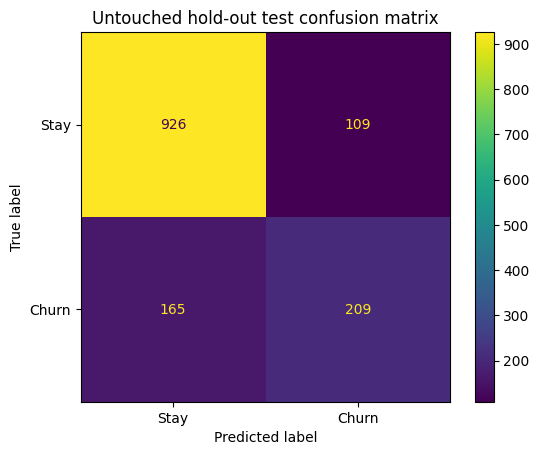

Limitations: correlation does not prove causation; deployment needs monitoring and fair-use review.


In [5]:
pred = selected.predict(X_test)
print('FINAL TEST EVALUATION - selected model:', chosen_name)
print(classification_report(y_test, pred, target_names=['Stay','Churn'], zero_division=0))
print('Final test ROC AUC:', round(roc_auc_score(y_test, selected.predict_proba(X_test)[:,1]), 3))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['Stay','Churn'])
plt.title('Untouched hold-out test confusion matrix'); plt.show()
assert len(pred) == len(y_test)
print('Limitations: correlation does not prove causation; deployment needs monitoring and fair-use review.')

## Phase 6: Deployment - working inference demonstration and monitoring plan
We save a pipeline containing cleaning transformations and model together. The cell below predicts one previously unseen hold-out row. In actual use: monitor feature distributions, missing rates, accuracy as labels arrive, fairness, and retrain after review.

**In simple words:** Deployment here means saving the trained model and showing that I can load it again to make a new prediction inside Colab. I am not claiming this is a live website.


In [6]:
os.makedirs('artifacts',exist_ok=True)
joblib.dump(selected,'artifacts/churn_model.joblib')
loaded=joblib.load('artifacts/churn_model.joblib')
new_customer=X_test.iloc[[0]]
prob=float(loaded.predict_proba(new_customer)[0,1])
print('Demo predicted probability of churn:',round(prob,3),'Actual label (held-out):',int(y_test.iloc[0]))
assert np.allclose(loaded.predict_proba(new_customer),selected.predict_proba(new_customer))
results.to_csv('artifacts/validation_model_comparison.csv')
print('Saved artifacts/churn_model.joblib and artifacts/validation_model_comparison.csv')

Demo predicted probability of churn: 0.045 Actual label (held-out): 0
Saved artifacts/churn_model.joblib and artifacts/validation_model_comparison.csv


## AI critique and revision record - actual review

**Critique context:** An AI assistant reviewed the complete executed version of this notebook, including its outputs, on 2026-11-02. This is one documented critique; it is not a claim that several separate reviews occurred.

**Review finding 1 (high priority):** The original notebook compared candidate models on the final test set. Even when the selected demonstration algorithm was fixed, using test results for comparison encouraged test-set peeking. **Revision:** Introduced a validation subset inside the training split; compare candidates only there; select by validation F1; refit on all original training data; report the untouched test results once.

**Review finding 2 (medium priority):** Business benefit was discussed but not measured. **Revision:** Added an explicit qualitative retention decision goal and distinguished illustrative value from measured financial benefit. Actual cost, intervention effectiveness and fairness are not known.

**Review finding 3 (high priority):** The original review section included prepared self-review bullets but no independent critique evidence. **Revision:** Documented real findings and associated changes from the current critique. Further critiques should be added here only after they have actually happened.